
## 1. Import Libraries & Load Dataset

Import the Python libraries.

Then load the train file as a pandas DataFrame.

Each row represents one operating cycle of an engine, containing its ID, cycle number, operating settings, and 21 sensor measurements.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    "../data/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset dimensions:", train.shape)
print("Number of engines:", train["engine_id"].nunique())

display(train.head(10))

Dataset dimensions: (20631, 26)
Number of engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,...,522.32,2388.03,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,...,522.47,2388.03,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,...,521.79,2388.05,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,...,521.79,2388.06,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694


In [19]:
# Find the final operating cycle of each engine
train["max_cycle"] = (
    train.groupby("engine_id")["cycle"].transform("max")
)

# Calculate Remaining Useful Life
train["RUL"] = train["max_cycle"] - train["cycle"]

display(train[["engine_id", "cycle", "RUL"]].head())

,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187



## 3. Calculate Remaining Useful Life (RUL)

Calculate the number of operating cycles remaining before each training engine reaches its simulated failure endpoint.

$$
RUL = T_{\mathrm{failure}} - t
$$

Where:
- $T_{\mathrm{failure}}$ is the engine's final operating cycle.
- $t$ is the current operating cycle.

RUL is the dependent variable in our regression model.

In [3]:

# Calculate the maximum recorded cycle for each engine
train["max_cycle"] = (
    train.groupby("engine_id")["cycle"].transform("max")
)

# Calculate Remaining Useful Life
train["RUL"] = train["max_cycle"] - train["cycle"]

# Inspect Engine 1
display(
    train.loc[
        train["engine_id"] == 1,
        ["engine_id", "cycle", "max_cycle", "RUL"]
    ].head(10)
)

# Inspect the final observation for Engine 1
display(
    train.loc[
        train["engine_id"] == 1,
        ["engine_id", "cycle", "max_cycle", "RUL"]
    ].tail(1)
)


,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


,engine_id,cycle,max_cycle,RUL
191,1,192,192,0



## 4. Engine Lifetime Distribution

Calculate descriptive statistics and plot the distribution of engine lifetimes.

This helps us understand the average engine lifetime and the variability between engines.


Engine lifetime descriptive statistics:


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

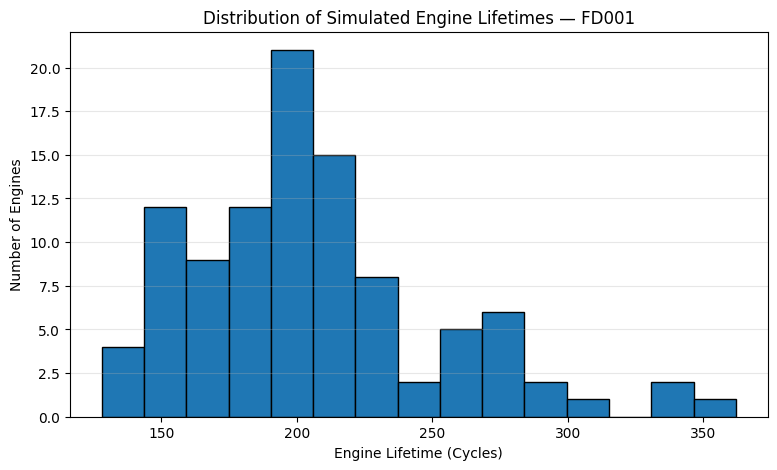

In [4]:

# One lifetime observation per engine
engine_lifetimes = train.groupby("engine_id")["cycle"].max()

print("Engine lifetime descriptive statistics:")
display(engine_lifetimes.describe())

plt.figure(figsize=(9, 5))

plt.hist(
    engine_lifetimes,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Engine Lifetime (Cycles)")
plt.ylabel("Number of Engines")
plt.title("Distribution of Simulated Engine Lifetimes — FD001")
plt.grid(axis="y", alpha=0.3)

plt.show()



## 5. Sensor Variability & Correlations

Calculate the standard deviation of each sensor to identify measurements with little or no variation.

Nearly constant sensors may provide limited information for predicting engine degradation.


In [5]:

sensors = [f"sensor_{i}" for i in range(1, 22)]

# 1. Identify sensors with little or no variation
variability = train[sensors].std().sort_values()
display(variability)

# 2. Calculate correlations with RUL
correlations = (
    train[sensors + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values(key=abs, ascending=False)
)

display(correlations)


sensor_1     0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_10    0.000000e+00
sensor_16    1.387812e-17
sensor_5     1.776400e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

sensor_11   -0.696228
sensor_4    -0.678948
sensor_12    0.671983
sensor_7     0.657223
sensor_15   -0.642667
sensor_21    0.635662
sensor_20    0.629428
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

Remove: 1, 5, 10, 16, 18, 19.

In [10]:
# Remove constant sensors from the predictor list
excluded_sensors = [1, 5, 10, 16, 18, 19]

selected_sensors = [
    f"sensor_{i}" for i in range(1, 22)
    if i not in excluded_sensors
]

print("Remaining sensors:", selected_sensors)
print("Number of sensors:", len(selected_sensors))

Remaining sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Number of sensors: 15



## Sensor Multicollinearity

Calculate Pearson correlation coefficients between the remaining 15 sensors.

Strong correlations between predictors may indicate multicollinearity. We will use these results to help select sensors for multiple linear regression.


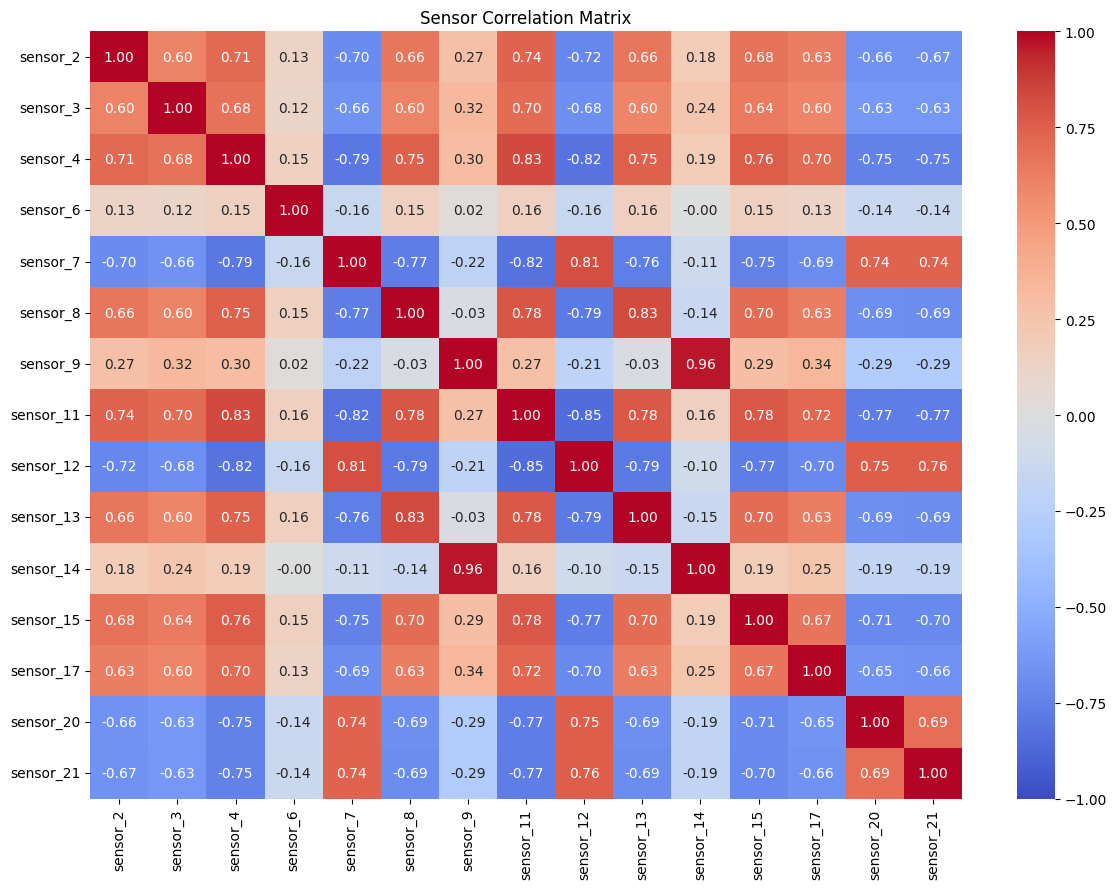

In [11]:

# Calculate correlations between the remaining sensors
correlation_matrix = train[selected_sensors].corr()

# Visualize correlations
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Sensor Correlation Matrix")
plt.tight_layout()
plt.show()


In [12]:

# Show highly correlated sensor pairs
for i, sensor_a in enumerate(selected_sensors):
    for sensor_b in selected_sensors[i + 1:]:
        r = correlation_matrix.loc[sensor_a, sensor_b]

        if abs(r) > 0.8:
            print(f"{sensor_a} vs {sensor_b}: r = {r:.3f}")


sensor_4 vs sensor_11: r = 0.830
sensor_4 vs sensor_12: r = -0.816
sensor_7 vs sensor_11: r = -0.823
sensor_7 vs sensor_12: r = 0.813
sensor_8 vs sensor_13: r = 0.826
sensor_9 vs sensor_14: r = 0.963
sensor_11 vs sensor_12: r = -0.847



## Predictor Selection

Identify sensors that are strongly associated with RUL but not excessively correlated with Sensor 11.

We use an absolute correlation of 0.8 as an initial screening threshold, not a strict statistical requirement.


In [13]:

# Correlation of each remaining sensor with Sensor 11
sensor_11_correlations = (
    correlation_matrix["sensor_11"]
    .drop("sensor_11")
    .sort_values(key=abs)
)

display(sensor_11_correlations)


sensor_6     0.160014
sensor_14    0.163408
sensor_9     0.274591
sensor_3     0.695900
sensor_17    0.722296
sensor_2     0.740020
sensor_20   -0.771510
sensor_21   -0.772554
sensor_13    0.780761
sensor_15    0.780913
sensor_8     0.782213
sensor_7    -0.822805
sensor_4     0.830136
sensor_12   -0.846884
Name: sensor_11, dtype: float64


## Baseline Linear Regression

Fit a linear regression model using Sensor 11 to predict Remaining Useful Life (RUL).

Ordinary Least Squares determines the coefficients that minimize the sum of squared prediction errors.


In [20]:
print(train.columns.tolist())

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'max_cycle', 'RUL']


In [21]:

# Define predictor and target
X = train[["sensor_11"]]
y = train["RUL"]

# Fit the model
model = LinearRegression()
model.fit(X, y)

# Display the regression equation
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print("R²:", model.score(X, y))



Intercept: 8644.062869768268
Coefficient: -179.5550118115122
R²: 0.48473356925621724



## Multiple Linear Regression

Fit an OLS regression model using two sensor measurements to estimate Remaining Useful Life.

Compare its training R² with the single-sensor baseline. Further validation is required to determine whether additional predictors improve predictions on unseen engines.


In [22]:

from sklearn.linear_model import LinearRegression

# Preliminary two-sensor model
predictors = ["sensor_11", "sensor_4"]

X = train[predictors]
y = train["RUL"]

mlr_model = LinearRegression()
mlr_model.fit(X, y)

print("Intercept:", mlr_model.intercept_)

for sensor, coefficient in zip(predictors, mlr_model.coef_):
    print(f"{sensor}: {coefficient:.4f}")

print("Training R²:", mlr_model.score(X, y))


Intercept: 8840.399953318916
sensor_11: -110.0103
sensor_4: -2.4860
Training R²: 0.517537316181556



## Model Validation

Divide the 100 training engines into fitting (80%) and validation (20%) groups.

Keep all observations from each engine together to avoid evaluating the model on engines used during fitting.

Compare the single-sensor and two-sensor models using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².


In [23]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Split by engine, not by individual observations
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    splitter.split(train, groups=train["engine_id"])
)

fit_data = train.iloc[fit_idx]
val_data = train.iloc[val_idx]

models = {
    "Sensor 11": ["sensor_11"],
    "Sensors 11 + 4": ["sensor_11", "sensor_4"]
}

results = []

for name, predictors in models.items():
    model = LinearRegression()
    model.fit(fit_data[predictors], fit_data["RUL"])

    predictions = model.predict(val_data[predictors])

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(val_data["RUL"], predictions),
        "RMSE": np.sqrt(mean_squared_error(val_data["RUL"], predictions)),
        "R²": r2_score(val_data["RUL"], predictions)
    })

display(pd.DataFrame(results).round(3))


,Model,MAE,RMSE,R²
0,Sensor 11,34.288,43.476,0.561
1,Sensors 11 + 4,32.603,41.516,0.600



## Validation Predictions and Residuals

Compare actual and predicted RUL values for the two-sensor regression model.

The residual is defined as:

$$
e_i = RUL_i - \widehat{RUL}_i
$$

Residuals help identify systematic prediction errors and limitations of the linear model.


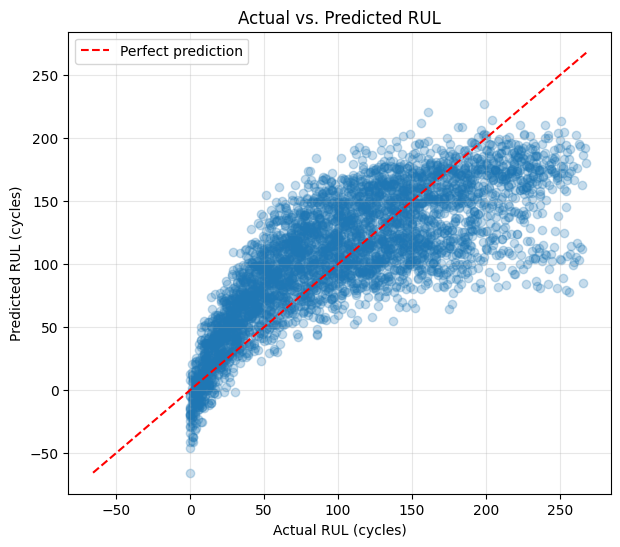

In [24]:

# Fit the two-sensor model
predictors = ["sensor_11", "sensor_4"]

model = LinearRegression()
model.fit(fit_data[predictors], fit_data["RUL"])

# Predict RUL for the validation engines
actual = val_data["RUL"]
predicted = model.predict(val_data[predictors])

# Plot actual versus predicted RUL
plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted, alpha=0.25)

# Perfect prediction reference line
limits = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs. Predicted RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## Comparison of Multiple Regression Models

Evaluate several combinations of engine sensors using the same training and validation groups.

Compare validation MAE, RMSE, and R² to determine whether additional predictors improve RUL prediction.


In [25]:

sensor_sets = {
    "2 sensors": ["sensor_11", "sensor_4"],
    "3 sensors": ["sensor_11", "sensor_4", "sensor_12"],
    "4 sensors": ["sensor_11", "sensor_4", "sensor_12", "sensor_7"]
}

results = []

for name, predictors in sensor_sets.items():
    model = LinearRegression()
    model.fit(fit_data[predictors], fit_data["RUL"])

    predicted = model.predict(val_data[predictors])
    actual = val_data["RUL"]

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    })

display(pd.DataFrame(results).round(3))


,Model,MAE,RMSE,R²
0,2 sensors,32.603,41.516,0.600
1,3 sensors,32.015,40.853,0.613
2,4 sensors,31.783,40.604,0.617



## Final Model Evaluation

Fit the selected multiple linear regression model using all 100 training engines.

Predict RUL at the last observed cycle of each of the 100 test engines and compare predictions with NASA's ground-truth RUL values.

Evaluate accuracy using MAE, RMSE, and R².


In [27]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Load official test data
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

test = pd.read_csv(
    "../data/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

true_rul = pd.read_csv(
    "../data/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

# Select final predictors
predictors = ["sensor_11", "sensor_4", "sensor_12", "sensor_7"]

# Fit model on all training observations
final_model = LinearRegression()
final_model.fit(train[predictors], train["RUL"])

# Take the final recorded cycle of every test engine
last_observations = (
    test.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
)

# Predict test RUL
predictions = final_model.predict(last_observations[predictors])

# Compare against NASA ground truth
actual = true_rul["RUL"].to_numpy()

assert len(predictions) == len(actual) == 100

print("Test MAE:", mean_absolute_error(actual, predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(actual, predictions)))
print("Test R²:", r2_score(actual, predictions))

print("\nRegression coefficients:")
print("Intercept:", final_model.intercept_)

for sensor, coefficient in zip(predictors, final_model.coef_):
    print(f"{sensor}: {coefficient:.4f}")


Test MAE: 28.137632481331583
Test RMSE: 35.33322554094539
Test R²: 0.2770520558545265

Regression coefficients:
Intercept: -6948.725121453403
sensor_11: -71.2349
sensor_4: -1.7197
sensor_12: 13.8114
sensor_7: 10.2366



## Final Test Predictions

Compare predicted RUL against NASA's actual RUL values for the 100 test engines.

Points near the diagonal indicate accurate predictions. Points above the diagonal represent overestimation, while points below represent underestimation.


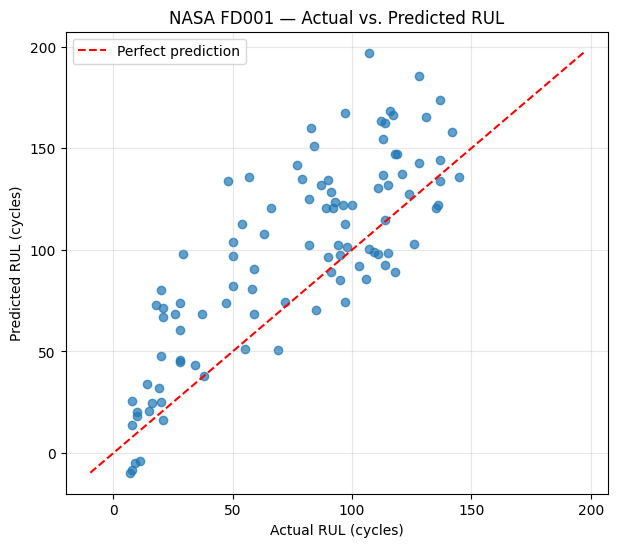

In [29]:

plt.figure(figsize=(7, 6))

plt.scatter(actual, predictions, alpha=0.7)

minimum = min(actual.min(), predictions.min())
maximum = max(actual.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("NASA FD001 — Actual vs. Predicted RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [30]:

# Baseline: always predict the mean training RUL
baseline_predictions = np.full(
    len(actual),
    train["RUL"].mean()
)

print(
    "Baseline MAE:",
    mean_absolute_error(actual, baseline_predictions)
)

print(
    "Baseline RMSE:",
    np.sqrt(mean_squared_error(actual, baseline_predictions))
)


Baseline MAE: 40.87930202123019
Baseline RMSE: 52.62485752612688


A multiple linear regression model using four C-MAPSS engine sensors achieved a test MAE of 28.14 cycles, RMSE of 35.33 cycles, and \(R^2\) of 0.277. The results demonstrate that sensor measurements contain information useful for estimating remaining engine life, although a linear model has substantial predictive limitations.

Initializing and Training Model

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

Finding Intercept and Slopes

In [ ]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Making Predictions

In [ ]:
y_pred = model.predict(X_test)

Visualizing Best- Fit Line in 3D

In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_test['MedInc'], X_test['AveRooms'],
           y_test, color='blue', label='Actual Data')

x1_range = np.linspace(X_test['MedInc'].min(), X_test['MedInc'].max(), 100)
x2_range = np.linspace(X_test['AveRooms'].min(), X_test['AveRooms'].max(), 100)
x1, x2 = np.meshgrid(x1_range, x2_range)

z = model.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)

ax.plot_surface(x1, x2, z, color='red', alpha=0.5, rstride=100, cstride=100)

ax.set_xlabel('Median Income')
ax.set_ylabel('Average Rooms')
ax.set_zlabel('House Price')
ax.set_title('Multiple Linear Regression Best Fit Line (3D)')

plt.show()